# Stories Café: Checking the Event Days

**Owner:** Omar Al-Aghbari (teammate 1, external evidence). **Inputs:** `data/stories_transactions.csv` (all rows kept) and the event list `data/external/external_events.json`.

**Question:** on the days the README flags and the days in the event list, were sales unusual, at which branch and at what time of day, and does that hold up once we account for how many days we looked at?

**Why the last part matters:** with 181 days, 4 branch groups and 4 times of day, there are 2,896 day/branch/time combinations. About 5% of them (around 145) will look "unusual" at the usual 95% threshold by chance alone. And several of these days were picked *because* they looked unusual, then explained with news afterwards. So we:
1. measure how far each day is from what's expected, given the growth trend and the weekday;
2. rank it against **every** day for the same branch and time of day;
3. apply a **multiple-testing correction** (Benjamini-Hochberg false discovery rate) across all 2,896 combinations.

**What this notebook doesn't do:** it doesn't say an event *caused* anything. Branch locations aren't confirmed, so even a very unusual day can't be tied to an event at a specific place (AGENTS.md).

**Sections**
1. Setup
2. Expected sales and how unusual each day is
3. The flagged and event days, by branch and time of day
4. Which of them survive the multiple-testing correction?
5. Comparison with the README's figures
6. Conclusion and status for the event list

## 1. Setup

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DAYPARTS = {"Morning (7-10)": (7, 10), "Afternoon (11-17)": (11, 17), "Evening (18-23)": (18, 23)}
GROUPS = ["All branches", "Harbour", "Garden", "Uptown"]
PARTS = ["Whole day", *DAYPARTS]
FDR = 0.05

# Days to check: the README's flagged days plus event-list days
CHECK_DAYS = {
    "2026-02-14": "Hariri anniversary: downtown road closures (ISF)",
    "2026-03-02": "War escalation begins",
    "2026-03-20": "Eid al-Fitr",
    "2026-03-21": "Eid al-Fitr, day 2",
    "2026-03-28": "README flagged day (conflict reporting)",
    "2026-04-08": "Mass strikes ('Black Wednesday')",
    "2026-04-17": "Ceasefire takes effect",
    "2026-05-01": "Labour Day",
    "2026-05-23": "Waterfront charity run, 06:30-12:00 (ISF)",
    "2026-06-05": "AUB graduate commencement (19:30)",
    "2026-06-06": "AUB undergraduate commencement (19:30)",
    "2026-06-24": "Waterfront displacement changes (candidate)",
}

INK, INK2, GRID, SURFACE, MUTED = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb", "#b9b8b3"
DIV = LinearSegmentedColormap.from_list("div", ["#a8302f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False,
})

df = pd.read_csv("../data/stories_transactions.csv")  # all rows kept, as agreed in AGENTS.md
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour
orders = df.groupby("Transaction ID").agg(date=("Date", "first"), hour=("hour", "first"), branch=("Branch", "first"))

events = json.loads(open("../data/external/external_events.json", encoding="utf-8").read())["events"]
print(f"{len(orders):,} orders over {orders['date'].nunique()} days; {len(events)} events in the event list")

33,887 orders over 181 days; 15 events in the event list


## 2. Expected sales and how unusual each day is

For each branch group and time of day, we fit daily orders with a **growth trend + weekday effect** on the log scale (the same approach as notebooks 02, 03 and 05) and take each day's distance from that fit. To judge "unusual", we divide that distance by a **robust** measure of normal day-to-day spread (the median absolute deviation), so a few extreme days don't hide each other. That gives a z-score: about ±2 is unusual for a single day, before correcting for the number of days checked.

In [2]:
def daily_counts(group, part):
    o = orders if group == "All branches" else orders[orders["branch"] == group]
    if part != "Whole day":
        lo, hi = DAYPARTS[part]
        o = o[o["hour"].between(lo, hi)]
    days = pd.date_range(orders["date"].min(), orders["date"].max())
    return o.groupby("date").size().reindex(days, fill_value=0)


def unusualness(counts):
    y = np.log(counts.to_numpy() + 1.0)
    t = (counts.index - counts.index[0]).days.to_numpy()
    dow = pd.get_dummies(counts.index.dayofweek, drop_first=True).to_numpy(float)
    X = np.column_stack([np.ones(len(t)), t, dow])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    scale = 1.4826 * np.median(np.abs(resid - np.median(resid)))
    expected = np.exp(X @ beta) - 1
    return pd.DataFrame({"orders": counts.to_numpy(), "expected": expected,
                         "vs_expected": counts.to_numpy() / expected - 1, "z": resid / scale}, index=counts.index)


rows = []
for g in GROUPS:
    for p in PARTS:
        u = unusualness(daily_counts(g, p))
        u["group"], u["part"] = g, p
        u["rank_pct"] = u["z"].abs().rank(pct=True)  # share of days that are less unusual
        rows.append(u.reset_index(names="date"))
screen = pd.concat(rows, ignore_index=True)
screen["p"] = 2 * stats.norm.sf(screen["z"].abs())
# Benjamini-Hochberg across all day/group/daypart combinations
m = len(screen)
order = screen["p"].rank(method="first").astype(int)
screen["q"] = (screen["p"] * m / order)
screen["q"] = screen.sort_values("p")["q"][::-1].cummin()[::-1].reindex(screen.index).clip(upper=1)
print(f"Combinations screened: {m:,}")
print(f"Unusual at the single-test 95% level (|z| > 1.96): {(screen['p'] < 0.05).sum()} "
      f"(about {0.05 * m:.0f} expected by chance)")
print(f"Surviving the false-discovery correction (q < {FDR}): {(screen['q'] < FDR).sum()}")

Combinations screened: 2,896
Unusual at the single-test 95% level (|z| > 1.96): 172 (about 145 expected by chance)
Surviving the false-discovery correction (q < 0.05): 3


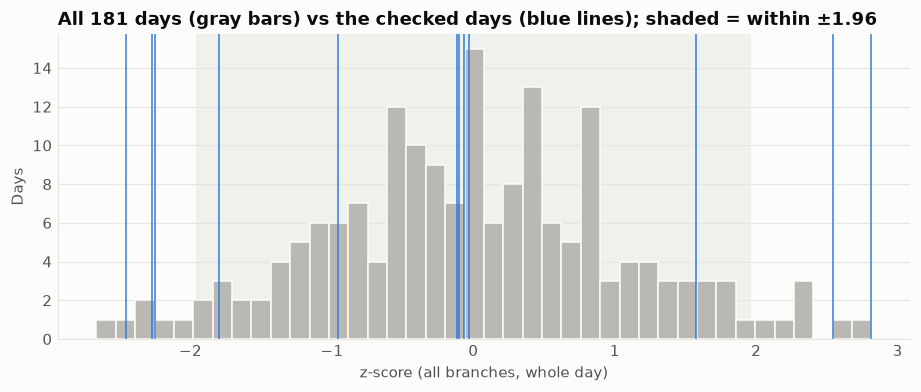

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.6))
z = screen.loc[(screen["group"] == "All branches") & (screen["part"] == "Whole day"), "z"]
ax.hist(z, bins=40, color=MUTED, edgecolor=SURFACE)
for d in CHECK_DAYS:
    v = screen.loc[(screen["group"] == "All branches") & (screen["part"] == "Whole day") & (screen["date"] == d), "z"].iat[0]
    ax.axvline(v, color="#2a78d6", lw=1.2, alpha=0.8)
ax.axvspan(-1.96, 1.96, color=GRID, alpha=0.5, lw=0, zorder=0)
ax.set_xlabel("z-score (all branches, whole day)")
ax.set_ylabel("Days")
ax.set_title("All 181 days (gray bars) vs the checked days (blue lines); shaded = within ±1.96")
ax.grid(axis="x", visible=False)
plt.show()

## 3. The flagged and event days, by branch and time of day

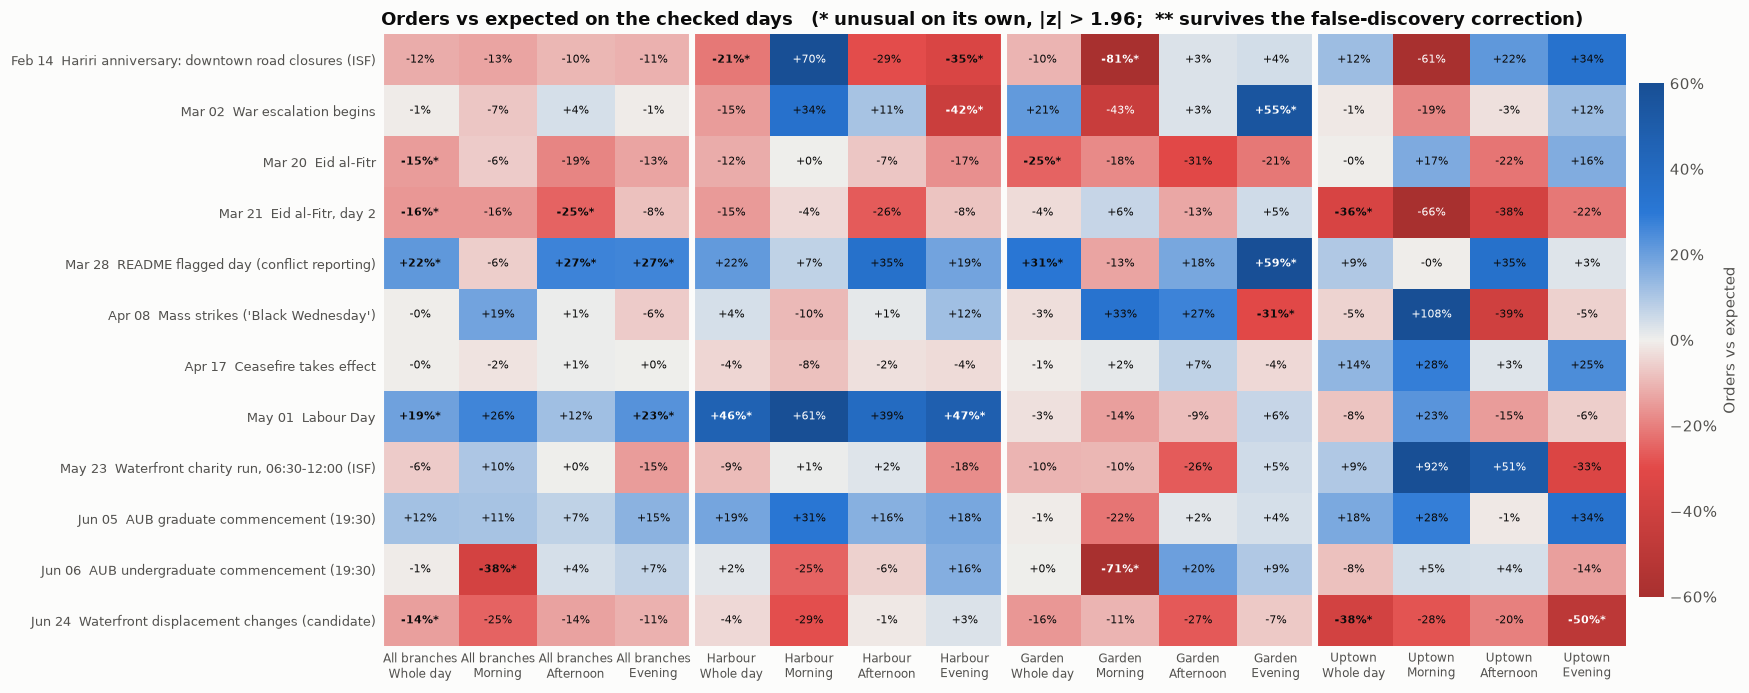

In [4]:
chk = screen[screen["date"].isin(pd.to_datetime(list(CHECK_DAYS)))].copy()
chk["label"] = chk["date"].dt.strftime("%b %d") + "  " + chk["date"].dt.strftime("%Y-%m-%d").map(CHECK_DAYS)
grid = chk.pivot_table(index="label", columns=["group", "part"], values="vs_expected", sort=False)
grid = grid.reindex(columns=pd.MultiIndex.from_product([GROUPS, PARTS]))
zgrid = chk.pivot_table(index="label", columns=["group", "part"], values="z", sort=False).reindex(columns=grid.columns)
qgrid = chk.pivot_table(index="label", columns=["group", "part"], values="q", sort=False).reindex(columns=grid.columns)

fig, ax = plt.subplots(figsize=(16, 6.4))
im = ax.imshow(grid.values, cmap=DIV, vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(grid.shape[1]), [f"{g}\n{p.split(' (')[0]}" for g, p in grid.columns], fontsize=8)
ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=8.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for j in range(0, grid.shape[1], len(PARTS)):
    ax.axvline(j - 0.5, color=SURFACE, lw=4)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v, zz, qq = grid.iat[i, j], zgrid.iat[i, j], qgrid.iat[i, j]
        mark = "**" if qq < FDR else ("*" if abs(zz) > 1.96 else "")
        ax.text(j, i, f"{v:+.0%}{mark}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.4 else INK, fontweight="bold" if mark else "normal")
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, format=mtick.PercentFormatter(1.0, decimals=0))
cb.set_label("Orders vs expected", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Orders vs expected on the checked days   (* unusual on its own, |z| > 1.96;  ** survives the false-discovery correction)")
plt.tight_layout()
plt.show()

In [5]:
summary = chk[chk["part"] == "Whole day"].pivot_table(index="label", columns="group", values="vs_expected", sort=False)[GROUPS]
summary.style.format("{:+.1%}").set_caption("Whole-day orders vs expected on the checked days")

group,All branches,Harbour,Garden,Uptown
label,,,,
Feb 14 Hariri anniversary: downtown road closures (ISF),-11.8%,-21.2%,-10.3%,+12.4%
Mar 02 War escalation begins,-0.8%,-14.8%,+21.2%,-1.0%
Mar 20 Eid al-Fitr,-14.6%,-11.9%,-25.3%,-0.2%
"Mar 21 Eid al-Fitr, day 2",-15.7%,-15.1%,-3.6%,-35.8%
Mar 28 README flagged day (conflict reporting),+21.6%,+21.6%,+30.9%,+9.4%
Apr 08 Mass strikes ('Black Wednesday'),-0.5%,+4.0%,-2.9%,-4.7%
Apr 17 Ceasefire takes effect,-0.2%,-4.4%,-0.5%,+14.3%
May 01 Labour Day,+19.3%,+45.6%,-2.8%,-7.6%
"May 23 Waterfront charity run, 06:30-12:00 (ISF)",-6.4%,-9.1%,-10.4%,+9.5%


## 4. Which of them survive the multiple-testing correction?

In [6]:
cols = ["date", "group", "part", "orders", "expected", "vs_expected", "z", "rank_pct", "q"]
hits = screen[screen["q"] < FDR].sort_values("q")[cols].copy()
hits["checked day?"] = hits["date"].dt.strftime("%Y-%m-%d").map(CHECK_DAYS).fillna("")
hits["date"] = hits["date"].dt.strftime("%a %b %d")
print(f"{len(hits)} of {len(screen):,} combinations survive (q < {FDR}).")
hits.style.format({"expected": "{:.1f}", "vs_expected": "{:+.0%}", "z": "{:+.2f}", "rank_pct": "{:.1%}", "q": "{:.3f}"}).hide(axis="index")

3 of 2,896 combinations survive (q < 0.05).


date,group,part,orders,expected,vs_expected,z,rank_pct,q,checked day?
Mon Jan 12,Harbour,Morning (7-10),2,8.3,-76%,-4.55,100.0%,0.015,
Fri Feb 06,Uptown,Morning (7-10),0,3.7,-100%,-4.40,100.0%,0.015,
Sun Jan 18,Uptown,Afternoon (11-17),2,8.2,-76%,-4.32,100.0%,0.015,


In [7]:
# How unusual is each checked day for its strongest branch/daypart, ranked against all days for that same cell?
best = chk.loc[chk.groupby("label")["z"].apply(lambda s: s.abs().idxmax())].copy()
best = best[["label", "group", "part", "vs_expected", "z", "rank_pct", "q"]].set_index("label")
best.rename(columns={"rank_pct": "more unusual than this share of days"}).style.format(
    {"vs_expected": "{:+.0%}", "z": "{:+.2f}", "more unusual than this share of days": "{:.1%}", "q": "{:.3f}"})

,group,part,vs_expected,z,more unusual than this share of days,q
label,,,,,,
Apr 08 Mass strikes ('Black Wednesday'),Garden,Evening (18-23),-31%,-1.98,93.9%,0.827
Apr 17 Ceasefire takes effect,Uptown,Evening (18-23),+25%,+1.00,63.0%,0.982
Feb 14 Hariri anniversary: downtown road closures (ISF),Garden,Morning (7-10),-81%,-3.28,100.0%,0.230
Jun 05 AUB graduate commencement (19:30),Harbour,Whole day,+19%,+1.60,91.2%,0.940
Jun 06 AUB undergraduate commencement (19:30),Garden,Morning (7-10),-71%,-2.85,99.4%,0.419
Jun 24 Waterfront displacement changes (candidate),Uptown,Evening (18-23),-50%,-3.04,98.3%,0.326
Mar 02 War escalation begins,Harbour,Evening (18-23),-42%,-3.65,100.0%,0.108
Mar 20 Eid al-Fitr,Garden,Whole day,-25%,-2.55,98.3%,0.568
"Mar 21 Eid al-Fitr, day 2",Uptown,Whole day,-36%,-2.66,97.8%,0.483


**How to read it:** for each checked day, this shows the branch and time of day where it looked most unusual. Remember that picking the most extreme of 16 cells per day is itself a form of searching, so even a high ranking here needs the corrected q-value (last column) to mean much.

## 5. Comparison with the README's figures

In [8]:
readme = pd.DataFrame([
    ("2026-02-14", "All branches", "Whole day", -0.185), ("2026-02-14", "Harbour", "Whole day", -0.289),
    ("2026-02-14", "Uptown", "Whole day", 0.015), ("2026-03-28", "All branches", "Whole day", 0.241),
    ("2026-03-28", "All branches", "Morning (7-10)", -0.138), ("2026-05-23", "All branches", "Whole day", -0.079),
    ("2026-05-23", "All branches", "Evening (18-23)", -0.165), ("2026-06-05", "All branches", "Whole day", 0.113),
    ("2026-06-05", "All branches", "Evening (18-23)", 0.145), ("2026-06-24", "All branches", "Whole day", -0.154),
    ("2026-06-24", "Uptown", "Whole day", -0.394), ("2026-06-24", "All branches", "Morning (7-10)", -0.275),
], columns=["date", "group", "part", "README (Codex rolling expected)"])
readme["date"] = pd.to_datetime(readme["date"])
cmp_ = readme.merge(screen[["date", "group", "part", "vs_expected", "q"]], on=["date", "group", "part"], how="left")
cmp_ = cmp_.rename(columns={"vs_expected": "This notebook (trend + weekday)"})
cmp_["date"] = cmp_["date"].dt.strftime("%b %d")
cmp_.style.format({"README (Codex rolling expected)": "{:+.1%}", "This notebook (trend + weekday)": "{:+.1%}", "q": "{:.3f}"}).hide(axis="index")

date,group,part,README (Codex rolling expected),This notebook (trend + weekday),q
Feb 14,All branches,Whole day,-18.5%,-11.8%,0.896
Feb 14,Harbour,Whole day,-28.9%,-21.2%,0.749
Feb 14,Uptown,Whole day,+1.5%,+12.4%,0.982
Mar 28,All branches,Whole day,+24.1%,+21.6%,0.419
Mar 28,All branches,Morning (7-10),-13.8%,-5.7%,0.994
May 23,All branches,Whole day,-7.9%,-6.4%,0.982
May 23,All branches,Evening (18-23),-16.5%,-14.6%,0.940
Jun 05,All branches,Whole day,+11.3%,+11.5%,0.940
Jun 05,All branches,Evening (18-23),+14.5%,+15.4%,0.940
Jun 24,All branches,Whole day,-15.4%,-14.4%,0.720


**Note:** the README's figures use a rolling expected value from the Codex pipeline (with its own daypart definitions), while this notebook uses a full-period trend + weekday fit. The two will differ somewhat; what matters is whether the direction agrees and whether the day survives a multiple-testing correction under either method.

## 6. Conclusion and status for the event list

**Overall:** of 2,896 day/branch/time combinations, 172 look unusual on their own (about 145 would by chance), and only **3 survive the false-discovery correction**. All 3 are low-count morning or afternoon cells in January and February (for example Uptown's morning on February 6, with 0 orders against 3.7 expected) that match none of the events. **None of the 12 checked days survives the correction**, at any branch or time of day.

| Day | Event | Whole day, all branches | Strongest cell | Survives correction? |
|---|---|---|---|---|
| Feb 14 | Hariri anniversary: downtown road closures | -12% | Garden morning -81% | No (q = 0.23) |
| Mar 2 | War escalation begins | -1% | Harbour evening -42% | No (q = 0.11) |
| Mar 20-21 | Eid al-Fitr | -15%, -16% | Uptown day 2 -36% | No (q ≥ 0.48) |
| Mar 28 | README flagged day | **+22%** | All branches, whole day | No (q = 0.42) |
| Apr 8 | Mass strikes | -1% | Garden evening -31% | No (q = 0.83) |
| Apr 17 | Ceasefire takes effect | 0% | Uptown evening +25% | No (q = 0.98) |
| May 1 | Labour Day | +19% | **Harbour whole day +46%** | No (q = 0.13) |
| May 23 | Waterfront charity run (morning) | -6% | Uptown evening -33% | No (q = 0.90) |
| Jun 5 | AUB graduate commencement | +12% | Harbour whole day +19% | No (q = 0.94) |
| Jun 6 | AUB undergraduate commencement | -1% | Garden morning -71% | No (q = 0.42) |
| Jun 24 | Waterfront displacement (candidate) | -14% | Uptown evening -50% (whole day -38%) | No (q = 0.33) |

**What this means**
- **Directions agree with the README** for every flagged day (section 5), with the network-level sizes close (for example June 24: -14.4% here vs -15.4%). The README's Harbour May 1 result passes its own screen (q = 0.023) but not this one (q = 0.13); the difference comes from the expected-value model and the number of combinations screened, so May 1 at Harbour is best described as **the strongest lead, not an established effect**.
- **Well-sourced events don't show unusual sales:** the war's first day, the April 8 strikes and the ceasefire are all within normal variation at the network level.
- **Event sources and sales evidence are separate questions.** The February 14 road closures and the May 23 waterfront run were first marked "not found" by teammate 1; the Codex teammate located the official ISF notices (`reports/source_reconciliation.md`) and teammate 1 confirmed them on 2026-10-17. Both events are now verified, but neither day survives the correction, and the run was in the morning while May 23's largest dip is in the evening.
- **Nothing here establishes a branch's exposure.** Until the company confirms locations and hours (`reports/company_information_request.md`), every event remains an alert in `data/external/external_events.json`, not a forecast input.